# 05 — Comparison, ablation, explainability
Master table, heatmap, ablations (cap/windows/smoothing/class-weight), permutation importance, limitations.

In [1]:
import sys; sys.path.insert(0,'..')
import pandas as pd
from pathlib import Path
from IPython.display import Image, display
base = Path('../results') if Path('../results/master_regression.csv').exists() else Path('results')
figbase = Path('../figures') if Path('../figures/master_rmse_heatmap.png').exists() else Path('figures')
ab=pd.read_csv(base/'ablations.csv')
print(ab[ab.subset=='FD001'].to_string())
perm=pd.read_csv(sorted(base.glob('FD001_importance_sensor_*.csv'))[0])
print(perm.head(10).to_string())

   subset      ablation                 setting     metric_name    cv_mean    cv_std  test_value
0   FD001      baseline                 default        rmse_cap  11.721063  0.452433   12.038364
1   FD001  smooth_order     legacy_smooth_first        rmse_cap  11.652343  0.424429   12.368993
2   FD001  smooth_order        fixed_norm_first        rmse_cap  11.721063  0.452433   12.038364
3   FD001       rolling                    [10]        rmse_cap  15.229226  0.692741   15.712877
4   FD001       rolling                [10, 30]        rmse_cap  11.721063  0.452433   12.038364
5   FD001       rolling             [5, 10, 30]        rmse_cap  11.643987  0.499217   12.529685
6   FD001       rul_cap                     100  rmse_common125   7.587283  0.405455   14.881663
7   FD001       rul_cap                     125  rmse_common125  11.706381  0.446489   11.962592
8   FD001       rul_cap                     130  rmse_common125  11.641345  0.422470   12.305166
9   FD001      no_cycle       

../figures/master_rmse_heatmap.png


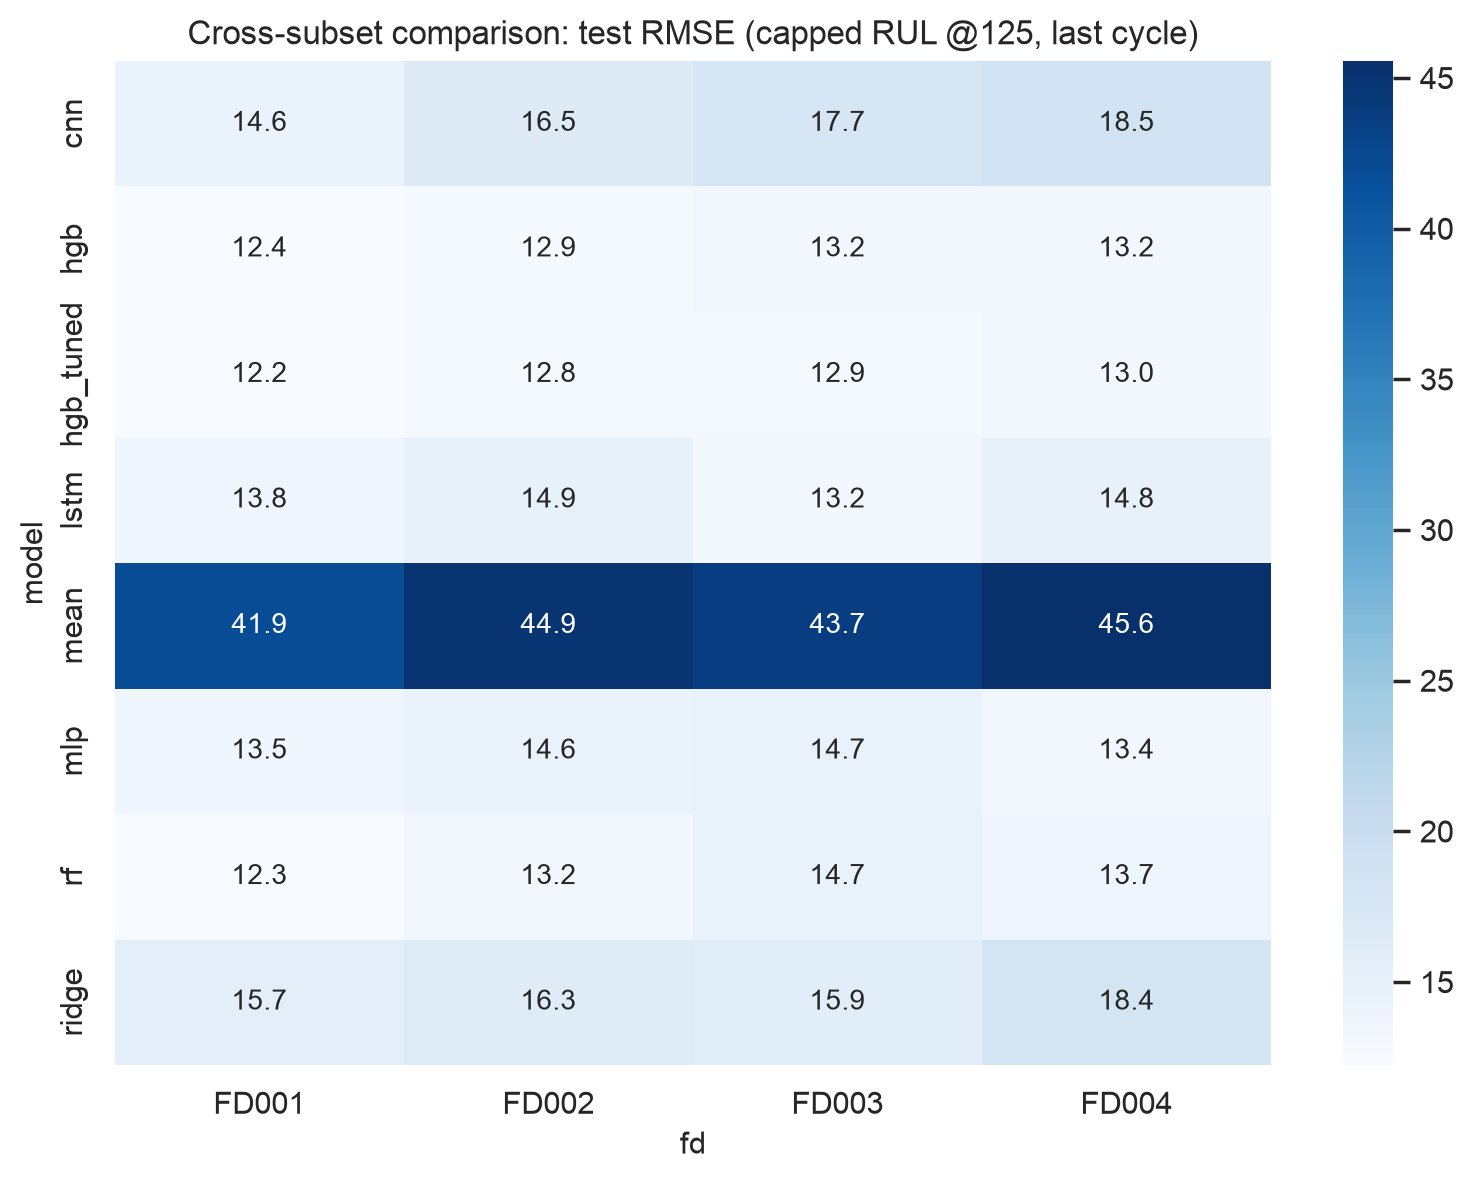

../figures/FD001_ablation_cap.png


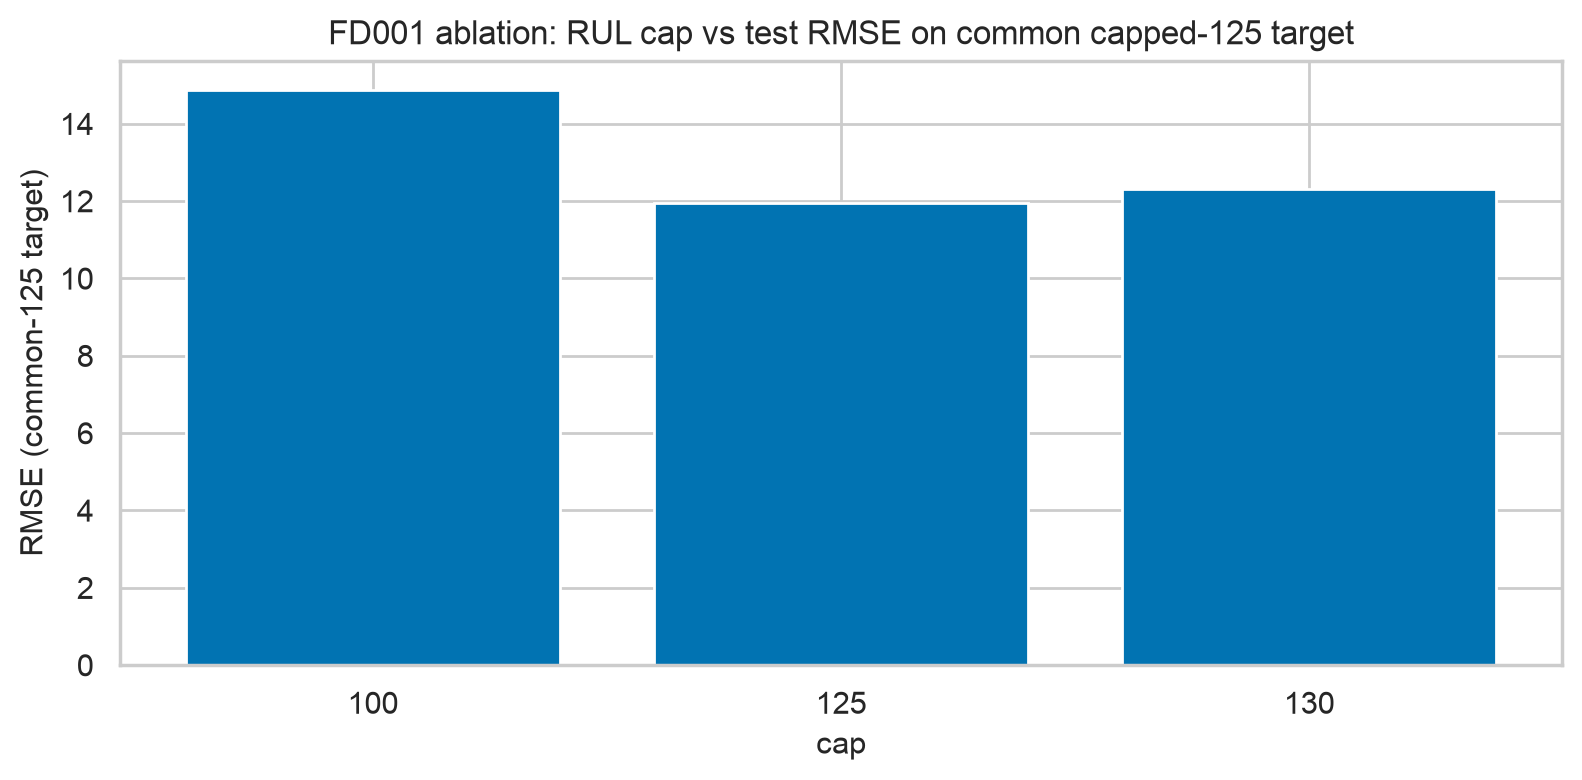

../figures/FD001_importance_sensor_hgb.png


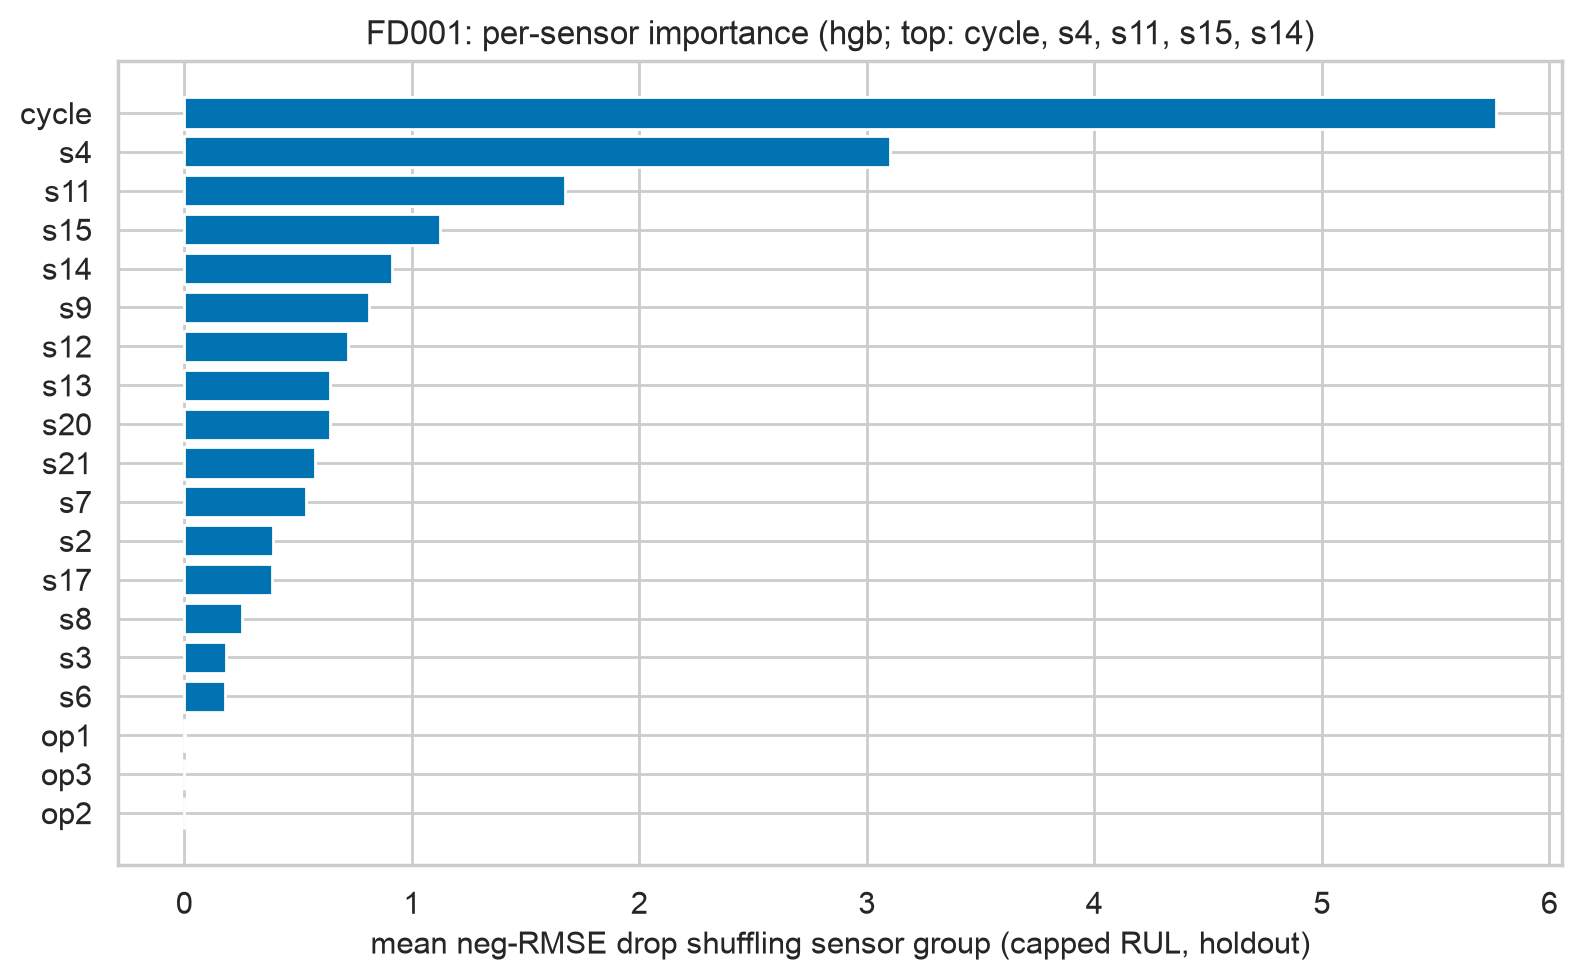

In [2]:
from IPython.display import Image, display
for f in [figbase/'master_rmse_heatmap.png', figbase/'FD001_ablation_cap.png']+sorted(figbase.glob('FD001_importance_sensor_*.png')):
    print(f)
    display(Image(filename=str(f),width=680))